In [3]:
from sympy import *

x, y,z = symbols('x y z')

init_printing(use_unicode=True)

In [11]:
simplify(sin(x)**2 + cos(x)**2)
simplify((x**3 + x**2 - x - 1)/(x**2 + 2*x + 1))
simplify(gamma(x)/gamma(x-2))

#doesn't always simplify, simplest is not objective
simplify(x**2 + 2*x + 1)
#use factor
factor(x**2 + 2*x + 1)

In [18]:
#Simplifying polynomial / rational functions

#Expand carries out the operations
expand((x+1)**2)
expand((x+2)*(x-3))

#Factor factorizes, opposite of expand
factor(x**3 - x**2 + x - 1)
factor(x**2*z + 4*x*y*z + 4*y**2*z)

#factor_list gives factors
factor_list(x**2*z + 4*x*y*z + 4*y**2*z)

#Handle also not polynomials
expand((cos(x) + sin(x))**2)
factor(cos(x)**2 + 2*cos(x)*sin(x) + sin(x)**2)

In [23]:
#Collect groups by power
expr = x*y + x - 3 + 2*x**2 - z*x**2 + x**3
collected_expr = collect(expr, x)
print(collected_expr)

collected_expr.coeff(x,2)

x**3 + x**2*(2 - z) + x*(y + 1) - 3


(y**2 - 2*y*z + z**2)/(x - 1)


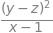

In [32]:
#Cancel reduces rational function into starndard canonical form
cancel((x**2 + 2*x + 1)/(x**2 + x))

expr = 1/x + (3*x/2 - 2)/(x-4)
cancel(expr)

expr = (x*y**2 - 2*x*y*z + x*z**2 + y**2 - 2*y*z + z**2)/(x**2 - 1)
print(cancel(expr))

#Factor can get a similar result but is less efficient
factor(expr)

In [44]:
#Trigonometric simplification
acos(x)
cos(acos(x))

#Simpplifies using trig identities
trigsimp(sin(x)**2 + cos(x)**2)
trigsimp(sin(x)**4 - 2*cos(x)**2*sin(x)**2 + cos(x)**4)

trigsimp(sin(x)*tan(x)/sec(x))

#and with hyperbolic trig functions too
trigsimp(cosh(x)**2 + sinh(x)**2)
trigsimp(sinh(x)/tanh(x))

#expand_trig 
expand_trig(sin(x+y))
expand_trig(tan(2*x))

#trigsimp can reverse expand_trig
trigsimp(sin(x)*cos(y) + sin(y)*cos(x))

In [53]:
#Powers
#Careful with square roots, because sympy performs simplifications
#only if true in general, but can put assumptions in symbols
#By default symbols are complex

x, y = symbols('x y', positive = True)
a, b = symbols('a b', real = True)
z, t, c = symbols('z t c')

#In sympy sqrt(x) = x**Rational(1,2)

#powsimp

powsimp(x**a*x**b)
powsimp(x**a*y**a)

#but
powsimp(t**c*z**c)

#can force simp
powsimp(t**c*z**c, force = True)

#sometimes rule (ab)**c = a**c*b**c is applied automatically
(z*t)**2
sqrt(x*y)

#so powsimp cannot put the bases together
powsimp(z**2*t**2)

In [62]:
#expand_power_exp / expand_power_base
#impose specific expansion

expand_power_exp(x**(a+b))
expand_power_base((x*y)**a)

#only applies valid identities, but can be forced
expand_power_base((z*t)**c) #not working
expand_power_base((z*t)**c, force=True)

#expand_power_exp(x**5) cannot split powers

#powdenest multiplies exponents
powdenest((x**a)**b) 
#also does not perform is generalization not valid
powdenest((z**a)**b)
#but can be forced
powdenest((z**a)**b, force = True)




In [88]:
#Special functions

x,y,z = symbols('x y z')
k,m,n = symbols('k m n')

#Factorial
factorial(n)

#Binomial coefficient
binomial(n, k)

#Gamma function
gamma(z)

#Hypergeometric fuctions
hyper([1,2], [3], z) 
#the first two coefficients determined the subscripts

#rewrite as a function of other functions
tan(x).rewrite(cos)
factorial(x).rewrite(gamma)

#expand functions in terms of some identities
expand_func(gamma(x+3))

#to expand hyper as easier functions
hyperexpand(hyper([1,1],[2],z))
 
#works also on Meijer G-function 
expr = meijerg([[1],[1]], [[1],[]], -z)
hyperexpand(expr)

#Simplify combinatorics
n,k = symbols('n k', integer = True)
combsimp(factorial(n)/factorial(n - 3))
combsimp(binomial(n+1, k+1)/binomial(n,k))

#gammasimp to simplifyy gammas and non-integer combinatorics
gammasimp(gamma(x)*gamma(1-x))


In [ ]:
#Example: Continued fractions
def list_to_frac(l):
    expr = Integer(0) #to go to sympy
    for i in reversed(l[1:]):
        expr += i
        expr = 1/expr
    return l[0] + expr

list_to_frac([x, y, z])

syms = symbols('a0:5') #gives symbols tuple
a0, a1, a2, a3, a4 = syms #creating variables
frac = list_to_frac(syms)

#in standard rational form
cancel(frac)

#Can do partial fraction decomposition w.r.t. 
# to a factor c not contained in f

l = []
frac = apart(frac, a0)
pprint(frac)

l.append(a0)
frac = 1/(frac - a0)
pprint(frac)

#can repeat the proccess identically and use 
#list to frac to obtain continued fraction form


               a₂⋅a₃⋅a₄ + a₂ + a₄           
a₀ + ───────────────────────────────────────
     a₁⋅a₂⋅a₃⋅a₄ + a₁⋅a₂ + a₁⋅a₄ + a₃⋅a₄ + 1
a₁⋅a₂⋅a₃⋅a₄ + a₁⋅a₂ + a₁⋅a₄ + a₃⋅a₄ + 1
───────────────────────────────────────
          a₂⋅a₃⋅a₄ + a₂ + a₄           


In [104]:
import random
l = list(symbols('a0:5'))
random.shuffle(l)
orig_frac = frac = cancel(list_to_frac(l))
pprint(orig_frac)

a₀⋅a₁⋅a₂⋅a₃⋅a₄ + a₀⋅a₁⋅a₃ + a₀⋅a₂⋅a₄ + a₀⋅a₃⋅a₄ + a₀ + a₁⋅a₂⋅a₄ + a₁ + a₄
─────────────────────────────────────────────────────────────────────────
                 a₁⋅a₂⋅a₃⋅a₄ + a₁⋅a₃ + a₂⋅a₄ + a₃⋅a₄ + 1                 
